In [18]:
from google.colab import drive
drive.mount('/content/drive')
import sys
sys.path.append('/content/drive/MyDrive/Colab Notebooks')

# import importlib
# import multiclass_functions
# importlib.reload(multiclass_functions)

from multiclass_functions import *
import torch
from torch import nn, optim
from torchvision import datasets, transforms
from torch.utils.data import TensorDataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt
import os
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(DEVICE)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
cuda


In [19]:
BATCH_SIZE = 32
LR = 1e-3
EPOCH = 5
criterion = nn.CrossEntropyLoss()
new_model_train = True
model_type = 'MLP'
dataset = 'MNIST'

save_dir = 'content/drive/MyDrive/Colab Notebooks/results'
os.makedirs(save_dir, exist_ok=True)

save_model_path = f'{save_dir}/{model_type}_{dataset}.pt'


In [20]:
transform = transforms.ToTensor()
train_DS = datasets.MNIST(root = 'content/drive/MyDrive/Colab Notebooks/data',
                          train=True, download=True, transform=transform)
test_DS = datasets.MNIST(root = 'content/drive/MyDrive/Colab Notebooks/data',
                         train=False, download=True, transform=transform)
train_DL = DataLoader(train_DS, batch_size = BATCH_SIZE, shuffle=True)
test_DL = DataLoader(test_DS, batch_size = BATCH_SIZE, shuffle=True)

In [21]:
class MLP(nn.Module):
  def __init__(self):
    super().__init__()
    self.linear = nn.Sequential(nn.Linear(28*28, 100),
                                nn.ReLU(),
                                nn.Linear(100, 10))

  def forward(self, x):
    x = torch.flatten(x, start_dim=1)
    x = self.linear(x)
    return x

In [22]:
model = globals()[model_type]().to(DEVICE)

Epoch : 1, train loss : 0.309
--------------------
Epoch : 2, train loss : 0.142
--------------------
Epoch : 3, train loss : 0.100
--------------------
Epoch : 4, train loss : 0.076
--------------------
Epoch : 5, train loss : 0.060
--------------------


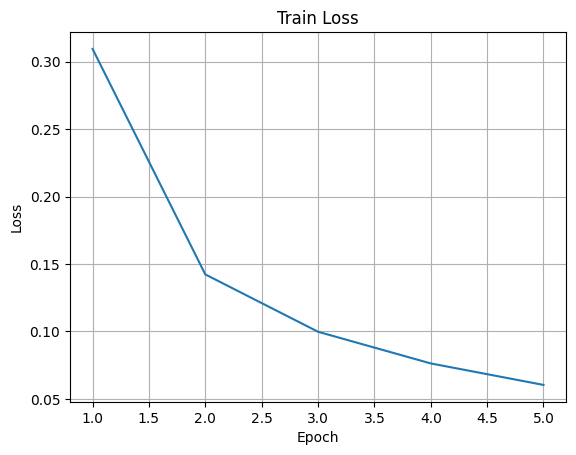

In [23]:
if new_model_train :
  optimizer = optim.Adam(model.parameters(), lr=LR)
  loss_history = Train(model, train_DL, criterion, optimizer, EPOCH)

  torch.save(model, save_model_path)

  plt.plot(range(1, EPOCH+1), loss_history)
  plt.xlabel('Epoch')
  plt.ylabel('Loss')
  plt.title('Train Loss')
  plt.grid()

In [24]:
load_model = torch.load(save_model_path,
                        map_location=DEVICE, weights_only=False)

In [25]:
Test(load_model, test_DL)
print(count_params(load_model))

Test accuracy : 9766 / 10000 (97.7 %)
79510


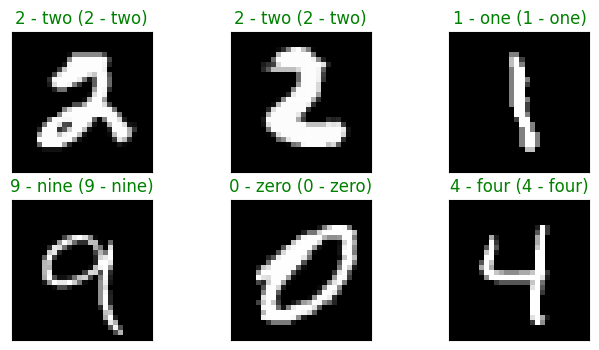

In [26]:
Test_plot(load_model, test_DL)